# Clean the Dataset

- Remove outliers based on 2std --> custom outlier removal based on data analysis. Too much data lost if we do 2 standard deviations away it seems.
- Remove duplicate edges
- Remove edges from nodes that are removed


TODO: Maybe change outlier removal to only do it on train set?


In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns

from torch_geometric.utils import to_dense_adj
from scipy.sparse import csr_array
from scipy.sparse.csgraph import connected_components

In [2]:
# Config
BASE_PATH_DATASET = Path("..", "data")
MIN_SIZE_BIGGEST_COMPONENT = 15

df_nodes = pd.read_csv(Path(BASE_PATH_DATASET, "original", "nodes.csv"))
df_edges = pd.read_csv(Path(BASE_PATH_DATASET, "original", "edges.csv"))

## Nodes

Remove rows with inf, and Nan


In [3]:
# keep for later
node_df_before_preprocess = df_nodes.copy()
edge_df_before_preprocess = df_edges.copy()

# actually preprocess
n_start = len(df_nodes)
num_cols = df_nodes.select_dtypes(include=np.number).columns
report = (
    pd.DataFrame(
        {
            "nan": df_nodes.isna().sum(),
            "inf": np.isinf(df_nodes[num_cols]).sum(),  # non-numeric columns (username) get NaN here
        }
    )
    .fillna(0)
    .astype(int)
)
report["total_bad"] = report["nan"] + report["inf"]
print(report)

# Remove inf and nan from the dataset
df_nodes_clean = df_nodes.replace([np.inf, -np.inf], np.nan).dropna()
print(
    f"\nAfter inf/NaN removal: {len(df_nodes_clean)} rows "
    f"(lost {n_start - len(df_nodes_clean)}, {100 * (1 - len(df_nodes_clean) / n_start):.1f}%)"
)


                   nan  inf  total_bad
accuracy             0    0          0
acpl                 0    0          0
avg_move_time        0   22         22
draw_rate            0    0          0
frac_blunders        0    0          0
frac_inaccuracies    0    0          0
frac_mistakes        0    0          0
last_theory_ply      0    0          0
loss_rate            0    0          0
loss_streak          0    0          0
num_games            0    0          0
num_moves            0    0          0
target_rating        0    0          0
username             0    0          0
win_rate             0    0          0
win_streak           0    0          0

After inf/NaN removal: 7549 rows (lost 22, 0.3%)


Have a look at outliers, and remove rows that are more than 2 std deviations from the mean


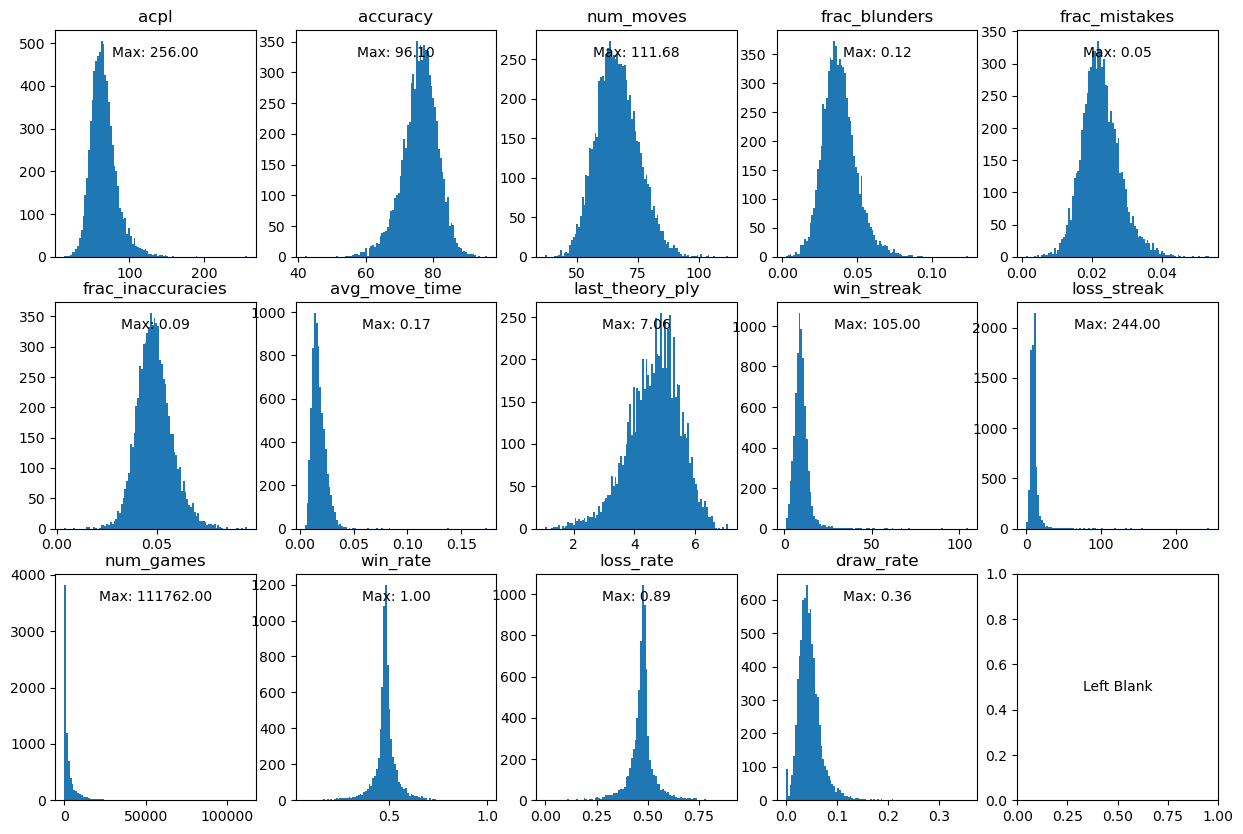

In [4]:
f = plt.figure(figsize=(15,10))
axs = f.subplots(3, 5)
for idx, feature in enumerate(df_nodes_clean.drop(['target_rating', 'username'], axis=1).columns):
    # print(idx)
    if feature == 'username':
        continue # skip usernames

    # print(f'max {feature}: {df_nodes_clean[feature].max()}')
    axs[idx // 5][idx % 5].hist(df_nodes_clean[feature], bins=100)#.set_title(f'Feature: {feature}')
    axs[idx // 5][idx % 5].set_title(feature)
    axs[idx // 5][idx % 5].text(0.5,0.9, f'Max: {df_nodes_clean[feature].max():.2f}', horizontalalignment='center', verticalalignment='center', transform=axs[idx // 5][idx % 5].transAxes)
    # plt.show()

axs[2][4].text(0.5,0.5, f'Left Blank', horizontalalignment='center', verticalalignment='center', transform=axs[2][4].transAxes)

plt.savefig('histogram_with_outliers.png', dpi=300)

## Outlier Removal

Based on a heuristic

In [5]:
# remove outliers based on custom analysis
df_nodes_clean = df_nodes_clean[df_nodes_clean['acpl'] < 150]
df_nodes_clean = df_nodes_clean[df_nodes_clean['avg_move_time'] < 0.050]
df_nodes_clean = df_nodes_clean[df_nodes_clean['win_streak'] < 30]
df_nodes_clean = df_nodes_clean[df_nodes_clean['loss_streak'] < 30]
df_nodes_clean = df_nodes_clean[df_nodes_clean['num_games'] < 40000]
df_nodes_clean = df_nodes_clean[df_nodes_clean['draw_rate'] < 0.20]
df_nodes_clean = df_nodes_clean.reset_index(drop=True)

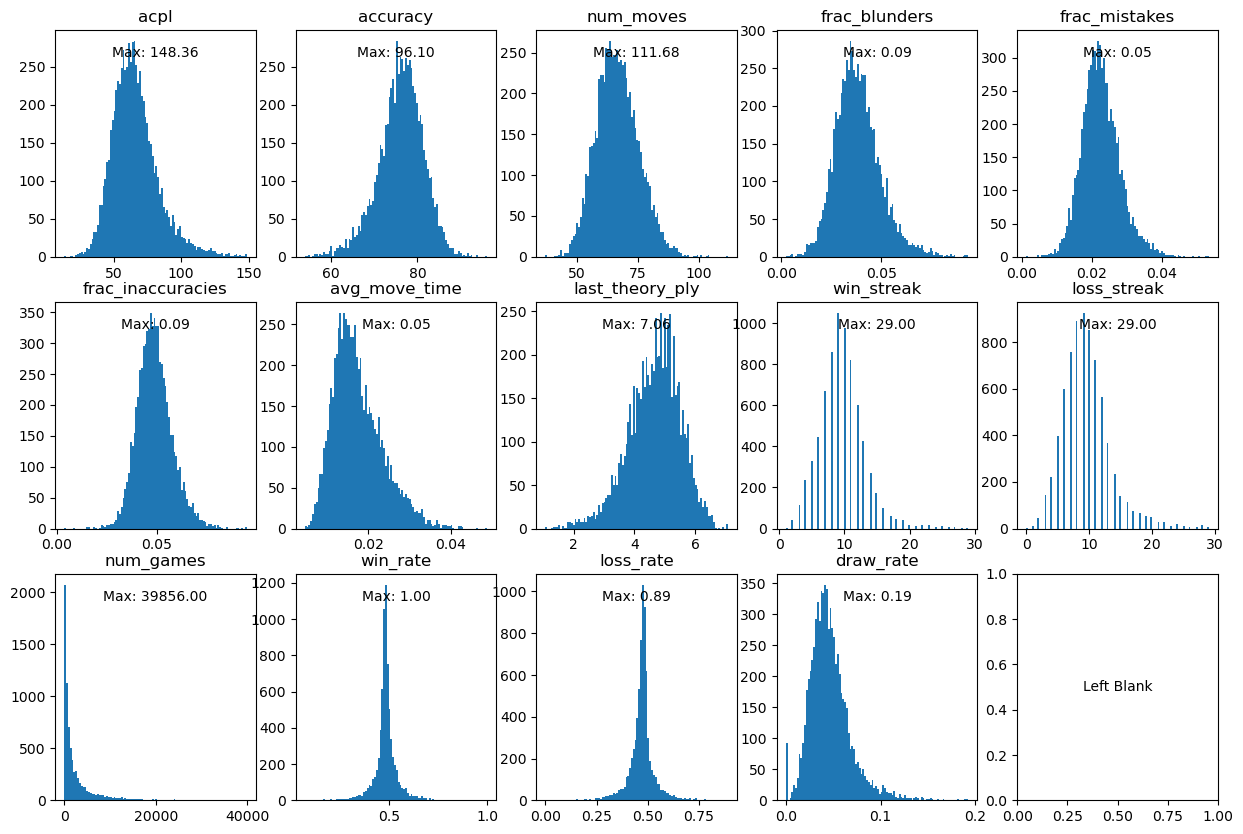

In [6]:
f = plt.figure(figsize=(15,10))
axs = f.subplots(3, 5)
for idx, feature in enumerate(df_nodes_clean.drop(['target_rating', 'username'], axis=1).columns):
    # print(idx)
    if feature == 'username':
        continue # skip usernames

    # print(f'max {feature}: {df_nodes_clean[feature].max()}')
    axs[idx // 5][idx % 5].hist(df_nodes_clean[feature], bins=100)#.set_title(f'Feature: {feature}')
    axs[idx // 5][idx % 5].set_title(feature)
    axs[idx // 5][idx % 5].text(0.5,0.9, f'Max: {df_nodes_clean[feature].max():.2f}', horizontalalignment='center', verticalalignment='center', transform=axs[idx // 5][idx % 5].transAxes)
    # plt.show()

axs[2][4].text(0.5,0.5, f'Left Blank', horizontalalignment='center', verticalalignment='center', transform=axs[2][4].transAxes)

plt.savefig('histogram_cleaned.png', dpi=300)

Remove edges from nodes that were removed

In [7]:
# check the difference in usernames: needed to remove relevant edges
diff = set(node_df_before_preprocess['username']) - set(df_nodes_clean['username'])

# remove edges that connect to the removed nodes
edges_to_be_removed = (df_edges['from'].isin(diff) | df_edges['to'].isin(diff)) # = either of the two ends has a removed node
df_edges = df_edges[~edges_to_be_removed]
df_edges = df_edges.reset_index(drop=True)

# delete old reference
del df_nodes

In [8]:
G = nx.DiGraph()
G.add_nodes_from(df_nodes_clean.drop_duplicates("username").set_index("username").to_dict("index").items())
G.add_weighted_edges_from(df_edges[["from", "to", "points"]].itertuples(index=False, name=None))

# Sanity check: no ghosts should remain
assert all(d for _, d in G.nodes(data=True)), "ghost nodes still present"
print(G.number_of_nodes(), G.number_of_edges())

7361 14578


In [9]:
n_ghost = sum(1 for _, d in G.nodes(data=True) if not d)
print(f"Nodes without attributes (ghosts): {n_ghost} of {G.number_of_nodes()}")

Nodes without attributes (ghosts): 0 of 7361


Nodes without attributes (ghosts): 0 of 7361
91 components, largest = 7181, nodes in largest = 97.6%


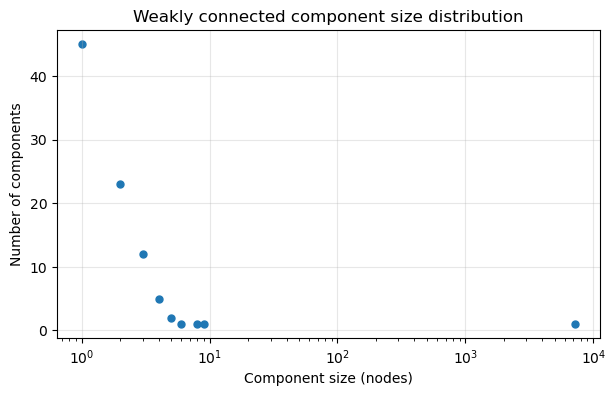

min_size=   2: keep 7316 nodes (99.4%), 46 components
min_size=   3: keep 7270 nodes (98.8%), 23 components
min_size=   5: keep 7214 nodes (98.0%), 6 components
min_size=  10: keep 7181 nodes (97.6%), 1 components
min_size=  50: keep 7181 nodes (97.6%), 1 components
min_size= 100: keep 7181 nodes (97.6%), 1 components


In [10]:
# Check for "ghost" nodes: edges pointing to users that were removed during cleaning
# have no attributes but still get created as nodes by add_weighted_edges_from.
n_ghost = sum(1 for _, d in G.nodes(data=True) if not d)
print(f"Nodes without attributes (ghosts): {n_ghost} of {G.number_of_nodes()}")

# Component sizes
components = list(nx.weakly_connected_components(G))
sizes = sorted((len(c) for c in components), reverse=True)
print(f"{len(components)} components, largest = {sizes[0]}, nodes in largest = {100 * sizes[0] / G.number_of_nodes():.1f}%")

size_counts = Counter(sizes)
xs, ys = zip(*sorted(size_counts.items()))

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(xs, ys, s=25)
ax.set_xscale("log")
ax.set_xlabel("Component size (nodes)")
ax.set_ylabel("Number of components")
ax.set_title("Weakly connected component size distribution")
ax.grid(alpha=0.3)
plt.show()

# Quick table of what a minimum-size cutoff would do
for min_size in [2, 3, 5, 10, 50, 100]:
    kept = sum(s for s in sizes if s >= min_size)
    print(
        f"min_size={min_size:>4}: keep {kept} nodes "
        f"({100 * kept / G.number_of_nodes():.1f}%), "
        f"{sum(1 for s in sizes if s >= min_size)} components"
    )

## Remove Components

In [11]:
MIN_SIZE = 30
keep = set().union(*(c for c in components if len(c) >= MIN_SIZE))
G_big = G.subgraph(keep).copy()

print(G_big.number_of_nodes(), G_big.number_of_edges())

# Keep your dataframe in sync with the graph
df_nodes_clean = df_nodes_clean[df_nodes_clean["username"].isin(keep)]

7181 14452


## Check again

Nodes without attributes (ghosts): 0 of 7181
1 components, largest = 7181, nodes in largest = 100.0%


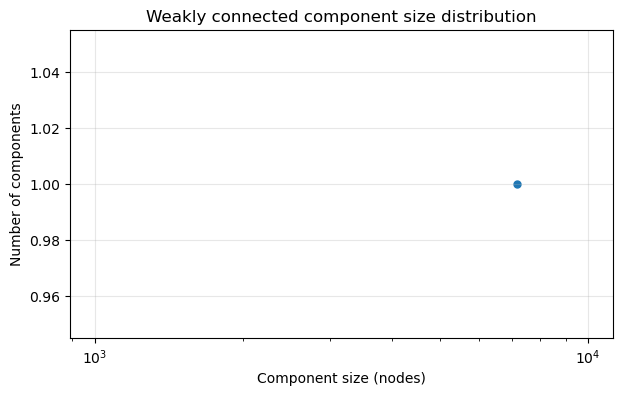

In [12]:
# Check for "ghost" nodes: edges pointing to users that were removed during cleaning
# have no attributes but still get created as nodes by add_weighted_edges_from.
n_ghost = sum(1 for _, d in G_big.nodes(data=True) if not d)
print(f"Nodes without attributes (ghosts): {n_ghost} of {G_big.number_of_nodes()}")

# Component sizes
components = list(nx.weakly_connected_components(G_big))
sizes = sorted((len(c) for c in components), reverse=True)
print(f"{len(components)} components, largest = {sizes[0]}, nodes in largest = {100 * sizes[0] / G_big.number_of_nodes():.1f}%")

size_counts = Counter(sizes)
xs, ys = zip(*sorted(size_counts.items()))

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(xs, ys, s=25)
ax.set_xscale("log")
ax.set_xlabel("Component size (nodes)")
ax.set_ylabel("Number of components")
ax.set_title("Weakly connected component size distribution")
ax.grid(alpha=0.3)
plt.show()

assert len(components) == 1, 'ERR: multiple components, expecting one.'

## Edges

Drop the duplicate edges, and make sure that both the source and the target node are still in the dataset.

In [13]:
# Remove edges from or to nodes that don't exist anymore
n_start_edges = len(df_edges)
valid_users = set(df_nodes_clean["username"])
df_edges = df_edges[df_edges["from"].isin(valid_users) & df_edges["to"].isin(valid_users)]

# Remove duplicates
df_deduplicated_edges = df_edges.drop_duplicates(["from", "to"], keep="first").reset_index(drop=True)
print(f"Edges: {n_start_edges} -> {len(df_edges)} -> {len(df_deduplicated_edges)}, "
    f"(lost {n_start_edges - len(df_deduplicated_edges)}, "
    f"{100 * (1 - len(df_deduplicated_edges) / n_start_edges):.1f}%)"
)

Edges: 20315 -> 20081 -> 14452, (lost 5863, 28.9%)


## Finally

Save the data.

In [14]:
df_deduplicated_edges.to_csv(Path(BASE_PATH_DATASET, "cleaned", "edges.csv"), index=False)
df_nodes_clean.to_csv(Path(BASE_PATH_DATASET, "cleaned", "nodes.csv"), index=False)